### Step 1.1: Import Required Libraries

In this step, we import the libraries required for data preprocessing, classification, model evaluation, cross-validation, and visualization.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt

# Data preprocessing
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    cross_val_predict
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Classification models
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Resampling
from sklearn.utils import resample

print("All libraries imported successfully!")

All libraries imported successfully!


### Step 1.2: Load the Dataset

In this step, we load the Student Performance Factors dataset using Pandas. We display its shape and first five rows to inspect the dataset.

In [2]:
# Locate the dataset
csv_files = list(
    Path("/kaggle/input").rglob("StudentPerformanceFactors.csv")
)

if not csv_files:
    raise FileNotFoundError("Dataset not found. Please attach it first.")

# Load dataset
df = pd.read_csv(csv_files[0])

# Display dataset information
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


### Step 1.3: Check Missing Values and Duplicate Records

Before preprocessing, we check the dataset for missing values and duplicate records. This helps identify data quality issues that need to be handled before model training.

In [3]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check duplicate records
print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Duplicate Rows:
0


### Step 1.4: Create the Target Variable and Engineer Features

We create a categorical target variable named `Needs_Support` using the `Exam_Score` column.

Students scoring below 65 are assigned class 1 (Needs Support), while students scoring 65 or above are assigned class 0 (No Support).

We also create two additional features: Study_Attendance_Interaction and Study_Sleep_Ratio.

In [4]:
# Create target variable
df["Needs_Support"] = (df["Exam_Score"] < 65).astype(int)

# Create additional features
df["Study_Attendance_Interaction"] = (
    df["Hours_Studied"] * df["Attendance"] / 100
)

df["Study_Sleep_Ratio"] = (
    df["Hours_Studied"] / df["Sleep_Hours"]
)

print("Target variable created successfully!")
print("New dataset shape:", df.shape)

Target variable created successfully!
New dataset shape: (6607, 23)


### Step 1.5: Analyze Class Balance

In this step, we examine the distribution of the target variable using `value_counts()` and visualize it with a bar chart.

This helps us identify the minority class and understand the class imbalance problem before training our models.

Target Class Distribution:
Needs_Support
0    5155
1    1452
Name: count, dtype: int64

Class Percentages:
Needs_Support
0    78.02
1    21.98
Name: count, dtype: float64


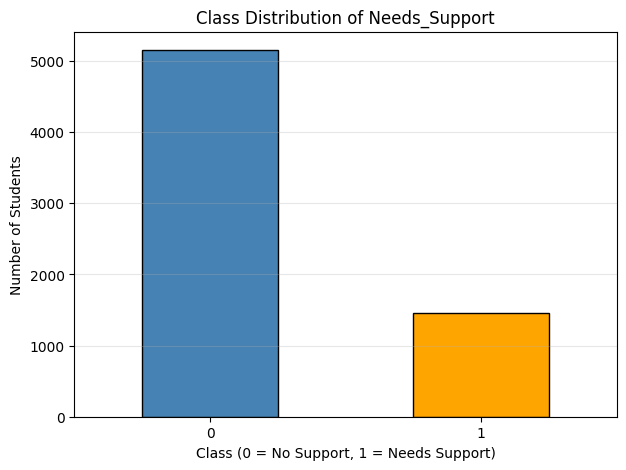

In [5]:
# Count records in each class
class_counts = df["Needs_Support"].value_counts().sort_index()

print("Target Class Distribution:")
print(class_counts)

# Calculate percentages
print("\nClass Percentages:")
print((class_counts / len(df) * 100).round(2))

# Visualize class distribution
plt.figure(figsize=(7, 5))

class_counts.plot(
    kind="bar",
    color=["steelblue", "orange"],
    edgecolor="black"
)

plt.title("Class Distribution of Needs_Support")
plt.xlabel("Class (0 = No Support, 1 = Needs Support)")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

### Step 1.6: Separate Features and Target Variable

We separate the independent features (X) from the target variable (y).

The Exam_Score column is excluded because it was used to create Needs_Support. Including it would cause target leakage.

In [6]:
# Separate input features and target
X = df.drop(columns=["Exam_Score", "Needs_Support"])
y = df["Needs_Support"]

# Display shapes
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (6607, 21)
Target Shape: (6607,)


### Step 1.7: Split the Dataset into Training and Testing Sets

We split the dataset into 80% training data and 20% testing data.

We use stratification to preserve the original class distribution in both sets. The test set will remain untouched until Step 7.

In [7]:
# Split the data while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display training data information
print("Training Features Shape:", X_train.shape)
print("Training Target Shape:", y_train.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts().sort_index())

Training Features Shape: (5285, 21)
Training Target Shape: (5285,)

Training Class Distribution:
Needs_Support
0    4124
1    1161
Name: count, dtype: int64


### Step 1.8: Identify Numerical and Categorical Features

We separate numerical and categorical columns so each type can receive appropriate preprocessing.

For numerical features, we use median imputation. For categorical features, we use the most frequent value and One-Hot Encoding. The preprocessing will be fitted only on training data to prevent data leakage.

In [8]:
# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Display feature counts
print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))
print("Total Features:", len(numeric_features) + len(categorical_features))

Numerical Features: 8
Categorical Features: 13
Total Features: 21


### Step 2.1: Train and Evaluate Baseline Models

We train a Dummy Classifier and a default Random Forest Classifier.

We use 5-fold cross-validation to generate predictions on the training data. We evaluate both models using accuracy, classification report, confusion matrix, and the number of minority-class cases missed (false negatives).

In [9]:
# 1. Create the Dummy Classifier pipeline
dummy_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

# 2. Create the default Random Forest pipeline
rf_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

# 3. Generate 5-fold cross-validation predictions
dummy_predictions = cross_val_predict(
    dummy_model, X_train, y_train, cv=5
)

rf_predictions = cross_val_predict(
    rf_baseline, X_train, y_train, cv=5
)

# 4. Evaluate both models
models = {
    "Dummy Classifier": dummy_predictions,
    "Random Forest": rf_predictions
}

for model_name, predictions in models.items():

    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)

    print("Accuracy:", round(
        accuracy_score(y_train, predictions), 4
    ))

    print("\nClassification Report:")
    print(classification_report(
        y_train,
        predictions,
        target_names=["No Support", "Needs Support"],
        zero_division=0
    ))

    cm = confusion_matrix(
        y_train, predictions, labels=[0, 1]
    )

    print("Confusion Matrix:")
    print(cm)

    tn, fp, fn, tp = cm.ravel()

    print("\nRare-class cases missed (False Negatives):", fn)


Dummy Classifier
Accuracy: 0.7803

Classification Report:
               precision    recall  f1-score   support

   No Support       0.78      1.00      0.88      4124
Needs Support       0.00      0.00      0.00      1161

     accuracy                           0.78      5285
    macro avg       0.39      0.50      0.44      5285
 weighted avg       0.61      0.78      0.68      5285

Confusion Matrix:
[[4124    0]
 [1161    0]]

Rare-class cases missed (False Negatives): 1161

Random Forest
Accuracy: 0.9145

Classification Report:
               precision    recall  f1-score   support

   No Support       0.92      0.98      0.95      4124
Needs Support       0.89      0.70      0.78      1161

     accuracy                           0.91      5285
    macro avg       0.91      0.84      0.86      5285
 weighted avg       0.91      0.91      0.91      5285

Confusion Matrix:
[[4026   98]
 [ 354  807]]

Rare-class cases missed (False Negatives): 354


### Step 3: Select the Evaluation Metric

In this classification problem, False Negatives are more harmful because students belonging to the Needs Support class may go unidentified.

Therefore, Recall is our primary evaluation metric. Higher recall means the model identifies more students who fall below the defined score threshold.

We will also monitor Precision to control unnecessary support flags and F1-score to balance Precision and Recall.

### Step 4.1: Identify False Negatives and False Positives

We compare the actual labels with the Random Forest predictions to identify four groups: True Negatives, False Positives, False Negatives, and True Positives.

This helps us isolate incorrectly classified records for further investigation.

In [10]:
# Create an error analysis DataFrame
error_analysis_df = X_train.copy()

error_analysis_df["Actual"] = y_train
error_analysis_df["Predicted"] = rf_predictions

# Categorize each prediction
conditions = [
    (error_analysis_df["Actual"] == 1) & (error_analysis_df["Predicted"] == 0),
    (error_analysis_df["Actual"] == 0) & (error_analysis_df["Predicted"] == 1),
    (error_analysis_df["Actual"] == 1) & (error_analysis_df["Predicted"] == 1),
    (error_analysis_df["Actual"] == 0) & (error_analysis_df["Predicted"] == 0)
]

choices = [
    "False Negative",
    "False Positive",
    "True Positive",
    "True Negative"
]

error_analysis_df["Prediction_Type"] = np.select(
    conditions,
    choices,
    default="Unknown"
)

# Display the number of records in each group
print("Prediction Group Counts:")
print(error_analysis_df["Prediction_Type"].value_counts())

# Separate incorrect predictions
false_negatives = error_analysis_df[
    error_analysis_df["Prediction_Type"] == "False Negative"
]

false_positives = error_analysis_df[
    error_analysis_df["Prediction_Type"] == "False Positive"
]

print("\nFalse Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))

print("\nSample False Negative Records:")
display(false_negatives.head())

print("\nSample False Positive Records:")
display(false_positives.head())

Prediction Group Counts:
Prediction_Type
True Negative     4026
True Positive      807
False Negative     354
False Positive      98
Name: count, dtype: int64

False Negatives: 354
False Positives: 98

Sample False Negative Records:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Study_Attendance_Interaction,Study_Sleep_Ratio,Actual,Predicted,Prediction_Type
5741,14,77,High,Low,No,7,54,Medium,Yes,1,...,2,No,High School,Moderate,Male,10.78,2.000000,1,0,False Negative
3422,23,68,High,Medium,No,6,60,Medium,Yes,1,...,3,No,High School,Near,Female,15.64,3.833333,1,0,False Negative
2558,22,69,Medium,Medium,Yes,6,91,Low,Yes,0,...,1,Yes,High School,Moderate,Male,15.18,3.666667,1,0,False Negative
3446,19,84,Low,Medium,Yes,8,56,Medium,Yes,0,...,3,Yes,High School,Near,Male,15.96,2.375000,1,0,False Negative
5754,19,80,High,Low,No,6,63,Low,Yes,1,...,3,No,High School,Near,Male,15.20,3.166667,1,0,False Negative



Sample False Positive Records:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Study_Attendance_Interaction,Study_Sleep_Ratio,Actual,Predicted,Prediction_Type
2210,12,68,Medium,High,No,7,98,Medium,Yes,1,...,4,No,High School,Near,Male,8.16,1.714286,0,1,False Positive
613,13,77,Medium,Medium,Yes,10,62,Medium,Yes,1,...,4,No,College,Moderate,Male,10.01,1.300000,0,1,False Positive
6233,5,96,Medium,Low,Yes,8,72,Low,Yes,3,...,5,No,High School,Near,Male,4.80,0.625000,0,1,False Positive
4617,3,99,Medium,Low,Yes,7,68,Medium,Yes,2,...,3,No,High School,Near,Female,2.97,0.428571,0,1,False Positive
5307,15,72,Medium,Low,Yes,9,80,Medium,Yes,4,...,4,No,College,Moderate,Female,10.80,1.666667,0,1,False Positive


### Step 4.2: Compare Numerical Features

We compare the average numerical feature values across the four prediction groups.

This helps us identify patterns that may explain why the Random Forest incorrectly classified some students.

Prediction_Type,False Negative,False Positive,True Negative,True Positive
Hours_Studied,18.69,14.96,21.28,14.54
Attendance,73.75,69.03,83.26,67.28
Sleep_Hours,6.97,7.06,7.03,7.08
Previous_Scores,69.55,79.32,76.00,72.50
Tutoring_Sessions,1.03,1.98,1.55,1.29
Physical_Activity,2.79,3.36,2.97,2.96
Study_Attendance_Interaction,13.43,10.08,17.56,9.66
Study_Sleep_Ratio,2.79,2.21,3.17,2.16


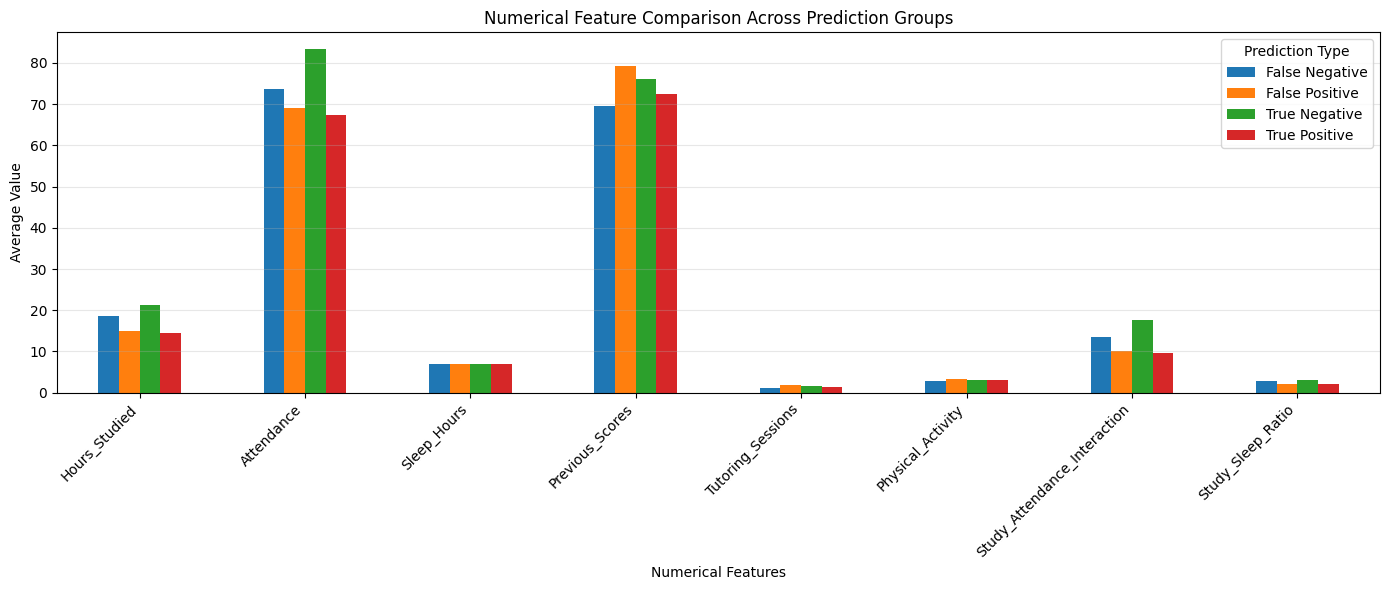

In [11]:
# Calculate average numerical feature values for each group
numeric_comparison = (
    error_analysis_df
    .groupby("Prediction_Type")[numeric_features]
    .mean()
    .T
)

# Display comparison
display(numeric_comparison.round(2))

# Visualize the comparison
numeric_comparison.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Numerical Feature Comparison Across Prediction Groups")
plt.xlabel("Numerical Features")
plt.ylabel("Average Value")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Prediction Type")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Step 4.3: Compare Categorical Features

We compare the category distributions of incorrectly classified students with correctly classified students.

We focus on False Negatives versus True Positives and False Positives versus True Negatives to identify categorical patterns that may explain classification errors.

In [12]:
# Compare categorical feature distributions
for col in categorical_features:

    print("\n" + "=" * 60)
    print("Feature:", col)
    print("=" * 60)

    comparison = pd.crosstab(
        error_analysis_df["Prediction_Type"],
        error_analysis_df[col],
        normalize="index"
    ) * 100

    display(comparison.round(1))


Feature: Parental_Involvement


Parental_Involvement,High,Low,Medium
Prediction_Type,,,
False Negative,15.0,34.5,50.6
False Positive,31.6,12.2,56.1
True Negative,31.1,18.1,50.7
True Positive,20.1,24.8,55.1



Feature: Access_to_Resources


Access_to_Resources,High,Low,Medium
Prediction_Type,,,
False Negative,17.8,30.5,51.7
False Positive,29.6,14.3,56.1
True Negative,32.9,17.8,49.3
True Positive,21.3,27.0,51.7



Feature: Extracurricular_Activities


Extracurricular_Activities,No,Yes
Prediction_Type,,
False Negative,46.0,54.0
False Positive,31.6,68.4
True Negative,38.1,61.9
True Positive,46.3,53.7


... (16 outputs left out)


Feature: Distance_from_Home


Distance_from_Home,Far,Moderate,Near
Prediction_Type,,,
False Negative,18.1,38.1,43.8
False Positive,4.1,28.9,67.0
True Negative,9.4,29.6,61.0
True Positive,11.3,32.4,56.3



Feature: Gender


Gender,Female,Male
Prediction_Type,,
False Negative,45.2,54.8
False Positive,36.7,63.3
True Negative,42.8,57.2
True Positive,40.5,59.5


### Categorical Error Analysis – Observations

1. False Negatives have higher percentages of low parental involvement (34.5% vs. 24.8%) and low family income (53.4% vs. 44.0%) compared with True Positives.

2. False Negatives also have higher percentages of students living far from school (18.1% vs. 11.3%) and experiencing negative peer influence (30.5% vs. 24.3%).

These patterns suggest that students with certain socioeconomic and environmental characteristics may be harder for the model to identify. However, these comparisons show associations, not causation.

### Step 5.1: Experiment 1 – Class Weight Balancing

We train a Random Forest Classifier using class_weight="balanced".

This assigns higher importance to the minority class during training. We use 5-fold cross-validation to evaluate whether this improves minority-class Precision, Recall, and F1-score.

All evaluation is performed using training data only.

In [13]:
# Create Random Forest with balanced class weights
rf_balanced = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

# Generate out-of-fold predictions
balanced_predictions = cross_val_predict(
    rf_balanced,
    X_train,
    y_train,
    cv=5
)

# Calculate baseline metrics
baseline_metrics = {
    "Precision": precision_score(y_train, rf_predictions, zero_division=0),
    "Recall": recall_score(y_train, rf_predictions, zero_division=0),
    "F1-score": f1_score(y_train, rf_predictions, zero_division=0)
}

# Calculate balanced model metrics
balanced_metrics = {
    "Precision": precision_score(y_train, balanced_predictions, zero_division=0),
    "Recall": recall_score(y_train, balanced_predictions, zero_division=0),
    "F1-score": f1_score(y_train, balanced_predictions, zero_division=0)
}

# Compare both models
comparison = pd.DataFrame(
    [baseline_metrics, balanced_metrics],
    index=["Baseline Random Forest", "Balanced Random Forest"]
)

display(comparison.round(4))

# Check false negatives
cm_balanced = confusion_matrix(
    y_train,
    balanced_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_balanced.ravel()

print("Balanced Random Forest Confusion Matrix:")
print(cm_balanced)
print("\nFalse Negatives:", fn)

,Precision,Recall,F1-score
Baseline Random Forest,0.8917,0.6951,0.7812
Balanced Random Forest,0.9147,0.6925,0.7882


Balanced Random Forest Confusion Matrix:
[[4049   75]
 [ 357  804]]

False Negatives: 357


### Experiment 1 – Observation

Class weighting improved Precision from 89.17% to 91.47% and F1-score from 0.7812 to 0.7882. However, Recall slightly decreased from 69.51% to 69.25%, and False Negatives increased from 354 to 357.

Therefore, class weighting alone did not improve minority-class detection.

### Step 5.2: Experiment 2 – Threshold Tuning

We experiment with different decision thresholds using the baseline Random Forest model.

Instead of using the default threshold of 0.5, we test thresholds of 0.4, 0.3, 0.2, and 0.1.

We generate out-of-fold probabilities using 5-fold cross-validation and compare Precision, Recall, and F1-score for the minority class.

In [14]:
# Generate out-of-fold probabilities for the minority class
rf_probabilities = cross_val_predict(
    rf_baseline,
    X_train,
    y_train,
    cv=5,
    method="predict_proba"
)[:, 1]

# Test different decision thresholds
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

threshold_results = []

for threshold in thresholds:

    predictions = (
        rf_probabilities > threshold
    ).astype(int)

    cm = confusion_matrix(
        y_train,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_train, predictions, zero_division=0
        ),
        "False Negatives": fn,
        "False Positives": fp
    })

# Display comparison table
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-score,False Negatives,False Positives
0,0.5,0.8917,0.6951,0.7812,354,98
1,0.4,0.8256,0.8157,0.8206,214,200
2,0.3,0.7141,0.9121,0.8011,102,424
3,0.2,0.5963,0.9681,0.7380,37,761
4,0.1,0.4558,0.9957,0.6254,5,1380


### Experiment 2 – Observation

Threshold tuning significantly improved minority-class detection.

At threshold 0.4, Recall increased from 69.51% to 81.57%, while F1-score improved from 0.7812 to 0.8206.

At threshold 0.3, Recall reached 91.21%, reducing False Negatives from 354 to 102. However, Precision decreased to 71.41%.

Threshold 0.4 provides the best F1-score, while 0.3 is a stronger candidate when Recall is the primary priority.

### Step 5.3: Experiment 3 – Random Oversampling

We use random oversampling to increase the representation of the minority class.

Within each cross-validation fold, we duplicate minority-class examples in the training portion until both classes have equal numbers of records.

The validation portion is never resampled. We then compare the model's Precision, Recall, and F1-score with our previous experiments.

In [15]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

# Create stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store out-of-fold predictions
oversampled_predictions = np.zeros(len(y_train), dtype=int)

# Perform oversampling separately inside each fold
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):

    # Separate fold training and validation data
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx].to_numpy()

    # Fit preprocessing only on this fold's training data
    fold_preprocessor = clone(preprocessor)

    X_fold_train_processed = fold_preprocessor.fit_transform(
        X_fold_train
    )

    X_fold_val_processed = fold_preprocessor.transform(
        X_fold_val
    )

    # Separate majority and minority classes
    majority_mask = y_fold_train == 0
    minority_mask = y_fold_train == 1

    X_majority = X_fold_train_processed[majority_mask]
    X_minority = X_fold_train_processed[minority_mask]

    y_majority = y_fold_train[majority_mask]
    y_minority = y_fold_train[minority_mask]

    # Oversample minority class
    X_minority_resampled, y_minority_resampled = resample(
        X_minority,
        y_minority,
        replace=True,
        n_samples=len(X_majority),
        random_state=42 + fold
    )

    # Combine both classes
    X_resampled = np.vstack([
        X_majority,
        X_minority_resampled
    ])

    y_resampled = np.concatenate([
        y_majority,
        y_minority_resampled
    ])

    # Train Random Forest on resampled training data
    fold_model = RandomForestClassifier(random_state=42)

    fold_model.fit(X_resampled, y_resampled)

    # Predict on the original, untouched validation fold
    oversampled_predictions[val_idx] = fold_model.predict(
        X_fold_val_processed
    )

    print(f"Fold {fold} completed")

# Evaluate oversampled model
oversampled_metrics = {
    "Precision": precision_score(
        y_train, oversampled_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_train, oversampled_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_train, oversampled_predictions, zero_division=0
    )
}

print("\nOversampled Random Forest Results:")
display(pd.DataFrame(
    [oversampled_metrics],
    index=["Random Oversampling"]
).round(4))

# Display confusion matrix
cm_oversampled = confusion_matrix(
    y_train,
    oversampled_predictions,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm_oversampled)

tn, fp, fn, tp = cm_oversampled.ravel()

print("\nFalse Negatives:", fn)
print("False Positives:", fp)

Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed

Oversampled Random Forest Results:


,Precision,Recall,F1-score
Random Oversampling,0.852,0.7881,0.8188


Confusion Matrix:
[[3965  159]
 [ 246  915]]

False Negatives: 246
False Positives: 159


### Step 5.4: Comparison of Model Improvement Experiments

We compare the baseline model with class weighting, threshold tuning, and random oversampling.

We focus on minority-class Precision, Recall, and F1-score to determine which experiment provides the most useful improvement.

In [16]:
experiment_summary = pd.DataFrame([
    {
        "Experiment": "Baseline RF",
        "Precision": 0.8917,
        "Recall": 0.6951,
        "F1-score": 0.7812
    },
    {
        "Experiment": "Class Weight Balanced",
        "Precision": 0.9147,
        "Recall": 0.6925,
        "F1-score": 0.7882
    },
    {
        "Experiment": "Threshold 0.4",
        "Precision": 0.8256,
        "Recall": 0.8157,
        "F1-score": 0.8206
    },
    {
        "Experiment": "Threshold 0.3",
        "Precision": 0.7141,
        "Recall": 0.9121,
        "F1-score": 0.8011
    },
    {
        "Experiment": "Threshold 0.2",
        "Precision": 0.5963,
        "Recall": 0.9681,
        "F1-score": 0.7380
    },
    {
        "Experiment": "Threshold 0.1",
        "Precision": 0.4558,
        "Recall": 0.9957,
        "F1-score": 0.6254
    },
    {
        "Experiment": "Random Oversampling",
        "Precision": 0.8520,
        "Recall": 0.7881,
        "F1-score": 0.8188
    }
])

display(
    experiment_summary.sort_values(
        by="Recall",
        ascending=False
    ).reset_index(drop=True).round(4)
)

,Experiment,Precision,Recall,F1-score
0,Threshold 0.1,0.4558,0.9957,0.6254
1,Threshold 0.2,0.5963,0.9681,0.7380
2,Threshold 0.3,0.7141,0.9121,0.8011
3,Threshold 0.4,0.8256,0.8157,0.8206
4,Random Oversampling,0.8520,0.7881,0.8188
5,Baseline RF,0.8917,0.6951,0.7812
6,Class Weight Balanced,0.9147,0.6925,0.7882


### Step 6.1: Calculate Feature Importance

We train the baseline Random Forest using the complete training dataset and calculate feature importance.

Since categorical features are One-Hot Encoded, we combine the importance of their encoded categories to calculate the importance of each original feature.

We then visualize the top 10 features.

Top 10 Most Important Features:


,Importance
Original_Feature,
Attendance,0.2304
Study_Attendance_Interaction,0.2108
Hours_Studied,0.0895
Study_Sleep_Ratio,0.0684
Previous_Scores,0.0557
Access_to_Resources,0.0361
Parental_Involvement,0.0336
Tutoring_Sessions,0.0280
Motivation_Level,0.0261


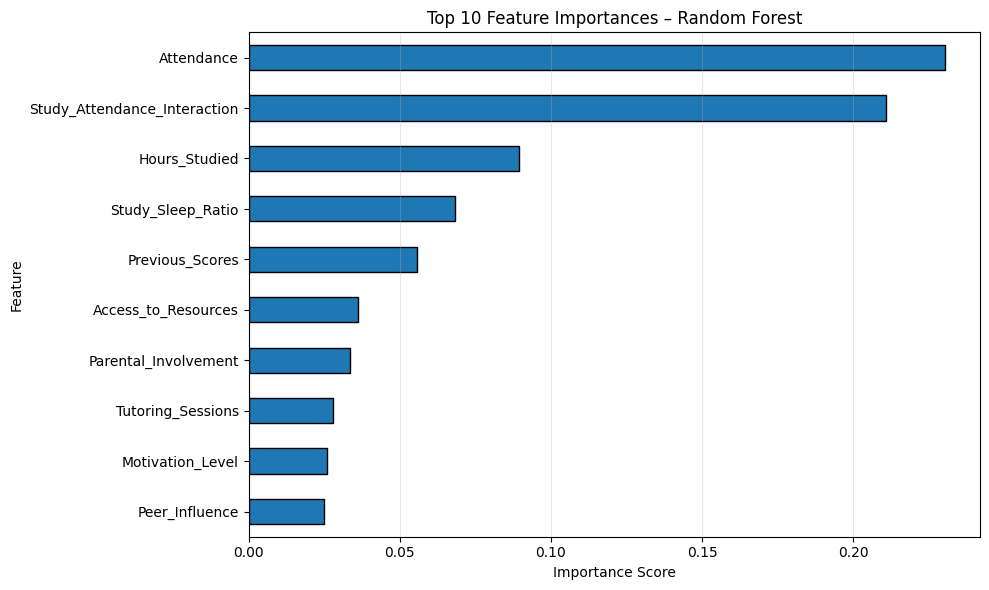


Top 3 Most Important Features:


,Importance
Original_Feature,
Attendance,0.2304
Study_Attendance_Interaction,0.2108
Hours_Studied,0.0895


In [17]:
# Train baseline Random Forest on the complete training data
rf_baseline.fit(X_train, y_train)

# Get transformed feature names and importance scores
transformed_names = (
    rf_baseline.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_values = (
    rf_baseline.named_steps["classifier"]
    .feature_importances_
)

# Create feature importance DataFrame
importance_df = pd.DataFrame({
    "Transformed_Feature": transformed_names,
    "Importance": importance_values
})

# Map encoded features back to original feature names
def get_original_feature(feature_name):

    feature_name = feature_name.split("__", 1)[1]

    matches = [
        col for col in X_train.columns
        if feature_name == col or feature_name.startswith(col + "_")
    ]

    return max(matches, key=len) if matches else feature_name

importance_df["Original_Feature"] = (
    importance_df["Transformed_Feature"]
    .apply(get_original_feature)
)

# Combine importance scores for original features
original_importance = (
    importance_df
    .groupby("Original_Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

# Display top 10 features
top_10 = original_importance.head(10)

print("Top 10 Most Important Features:")
display(top_10.to_frame().round(4))

# Visualize feature importance
plt.figure(figsize=(10, 6))

top_10.sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Top 10 Feature Importances – Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Display top 3 features
print("\nTop 3 Most Important Features:")
display(top_10.head(3).to_frame().round(4))

### Step 6.2: Evaluate Feature Removal

We remove the five least important original features identified using an internal training split.

We compare the full-feature Random Forest with the reduced-feature Random Forest on the same validation data, using a decision threshold of 0.3.

This helps determine whether removing less useful features improves minority-class detection.

In [18]:
from sklearn.base import clone

# Create an internal training and validation split
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Identify feature types
numeric_sub = X_subtrain.select_dtypes(
    include=np.number
).columns.tolist()

categorical_sub = X_subtrain.select_dtypes(
    exclude=np.number
).columns.tolist()


# Helper function to create a preprocessing pipeline
def make_preprocessor(numeric_cols, categorical_cols):

    return ColumnTransformer([
        ("num", clone(numeric_transformer), numeric_cols),
        ("cat", clone(categorical_transformer), categorical_cols)
    ])


# Train full-feature model
full_model = Pipeline([
    ("preprocessor", make_preprocessor(
        numeric_sub, categorical_sub
    )),
    ("classifier", RandomForestClassifier(random_state=42))
])

full_model.fit(X_subtrain, y_subtrain)

# Calculate feature importance using subtraining data
feature_names = (
    full_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_values = (
    full_model.named_steps["classifier"]
    .feature_importances_
)

importance_validation = pd.DataFrame({
    "Transformed_Feature": feature_names,
    "Importance": feature_values
})


# Map encoded features to their original columns
def map_original_feature(feature_name):

    feature_name = feature_name.split("__", 1)[1]

    matches = [
        col for col in X_subtrain.columns
        if feature_name == col or feature_name.startswith(col + "_")
    ]

    return max(matches, key=len) if matches else feature_name


importance_validation["Original_Feature"] = (
    importance_validation["Transformed_Feature"]
    .apply(map_original_feature)
)

# Aggregate importance by original feature
original_importance_validation = (
    importance_validation
    .groupby("Original_Feature")["Importance"]
    .sum()
    .sort_values()
)

# Identify five least important features
least_important_features = (
    original_importance_validation.head(5).index.tolist()
)

print("Five Features Selected for Removal:")
print(least_important_features)

# Keep the remaining features
selected_features = [
    col for col in X_subtrain.columns
    if col not in least_important_features
]

print("\nRemaining Features:", len(selected_features))


# Train reduced-feature model
reduced_numeric = [
    col for col in numeric_sub if col in selected_features
]

reduced_categorical = [
    col for col in categorical_sub if col in selected_features
]

reduced_model = Pipeline([
    ("preprocessor", make_preprocessor(
        reduced_numeric, reduced_categorical
    )),
    ("classifier", RandomForestClassifier(random_state=42))
])

reduced_model.fit(
    X_subtrain[selected_features],
    y_subtrain
)


# Generate validation probabilities
full_probabilities = full_model.predict_proba(X_val)[:, 1]

reduced_probabilities = reduced_model.predict_proba(
    X_val[selected_features]
)[:, 1]


# Apply the same threshold to both models
threshold = 0.3

full_predictions = (
    full_probabilities > threshold
).astype(int)

reduced_predictions = (
    reduced_probabilities > threshold
).astype(int)


# Compare validation performance
def evaluate_validation(y_true, predictions):

    cm = confusion_matrix(y_true, predictions, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    return {
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "False Negatives": fn,
        "False Positives": fp
    }


feature_removal_comparison = pd.DataFrame([
    evaluate_validation(y_val, full_predictions),
    evaluate_validation(y_val, reduced_predictions)
], index=["Full Features", "Reduced Features"])

print("\nValidation Performance Comparison:")
display(feature_removal_comparison.round(4))

Five Features Selected for Removal:
['Internet_Access', 'School_Type', 'Gender', 'Learning_Disabilities', 'Extracurricular_Activities']

Remaining Features: 16

Validation Performance Comparison:


,Precision,Recall,F1-score,False Negatives,False Positives
Full Features,0.7219,0.9397,0.8165,14,84
Reduced Features,0.7128,0.9095,0.7992,21,85


### Feature Removal – Observations

We removed the five least important features: Internet_Access, School_Type, Gender, Learning_Disabilities, and Extracurricular_Activities.

The reduced-feature model achieved a Recall of 90.95% and F1-score of 0.7992, compared with 93.97% Recall and 0.8165 F1-score for the full-feature model.

False Negatives increased from 14 to 21 after feature removal.

Therefore, we retained all 21 features because removing the selected features reduced model performance.

### Step 7.1: Final Evaluation on the Test Set

We evaluate the baseline Random Forest (threshold 0.5) and the improved Random Forest (threshold 0.3) on the reserved test set.

The model is trained using the complete training data. We generate test probabilities once and use them to compare both decision thresholds.

We report Accuracy, Precision, Recall, F1-score, and confusion matrices for the minority class.

In [19]:
# Train the final Random Forest using all training data
rf_baseline.fit(X_train, y_train)

# Generate test probabilities once
test_probabilities = rf_baseline.predict_proba(X_test)[:, 1]

# Baseline predictions: default threshold 0.5
baseline_test_predictions = (
    test_probabilities > 0.5
).astype(int)

# Improved predictions: selected threshold 0.3
final_test_predictions = (
    test_probabilities > 0.3
).astype(int)


# Function to calculate evaluation metrics
def calculate_test_metrics(y_true, predictions):

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        )
    }


# Calculate metrics
baseline_test_metrics = calculate_test_metrics(
    y_test, baseline_test_predictions
)

final_test_metrics = calculate_test_metrics(
    y_test, final_test_predictions
)


# Create before-and-after comparison
final_comparison = pd.DataFrame([
    {
        "Version": "Baseline RF (0.5)",
        **baseline_test_metrics
    },
    {
        "Version": "Improved RF (0.3)",
        **final_test_metrics
    }
])

print("FINAL TEST PERFORMANCE COMPARISON:")
display(final_comparison.round(4))


# Confusion matrices
baseline_cm = confusion_matrix(
    y_test, baseline_test_predictions, labels=[0, 1]
)

final_cm = confusion_matrix(
    y_test, final_test_predictions, labels=[0, 1]
)

print("\nBaseline Confusion Matrix:")
print(baseline_cm)

print("\nImproved Model Confusion Matrix:")
print(final_cm)


# False Negatives and False Positives
tn, fp, fn, tp = final_cm.ravel()

print("\nImproved Model Error Analysis:")
print("False Negatives:", fn)
print("False Positives:", fp)


# Detailed report for the final model
print("\nFinal Model Classification Report:")
print(classification_report(
    y_test,
    final_test_predictions,
    target_names=["No Support", "Needs Support"],
    zero_division=0
))

FINAL TEST PERFORMANCE COMPARISON:


,Version,Accuracy,Precision,Recall,F1-score
0,Baseline RF (0.5),0.9062,0.8553,0.6907,0.7643
1,Improved RF (0.3),0.9024,0.7238,0.9003,0.8025



Baseline Confusion Matrix:
[[997  34]
 [ 90 201]]

Improved Model Confusion Matrix:
[[931 100]
 [ 29 262]]

Improved Model Error Analysis:
False Negatives: 29
False Positives: 100

Final Model Classification Report:
               precision    recall  f1-score   support

   No Support       0.97      0.90      0.94      1031
Needs Support       0.72      0.90      0.80       291

     accuracy                           0.90      1322
    macro avg       0.85      0.90      0.87      1322
 weighted avg       0.92      0.90      0.91      1322



### Step 7.2: Final Model Selection and Conclusion

The improved Random Forest with a decision threshold of 0.3 achieved 90.03% Recall and an F1-score of 80.25% on the unseen test set.

Compared with the baseline model, Recall increased from 69.07% to 90.03%, while False Negatives decreased from 90 to 29.

However, Precision decreased from 85.53% to 72.38%, and False Positives increased from 34 to 100. Accuracy also decreased slightly from 90.62% to 90.24%.

We selected the improved model because identifying more students in the score-defined Needs Support class is our primary objective. The additional false positives represent a tradeoff that may be acceptable when early support is relatively inexpensive.

Overall, threshold tuning provided the most effective improvement in minority-class detection among our experiments.